# Ejercicio Tarea

![Logo Itq](img/ITQ.png)

**Nombre:** Angelica Paredes

**Fecha:** 20/11/2026

**Link del repositorio:** <a href="https://github.com/AngelicaPar/FundamentosMachineLearning26-27/blob/main/Paredes_Angelica_Practica_Datos_Medicos.ipynb">Link Repositorio</a>

# Normalización y estandarización de datos médicos con CRISP DM

# Objetivos
Aplicar las fases de comprensión del negocio y comprensión de los datos de CRISP-DM, y desarrollar la preparación de datos hasta la normalización Min-Max y la estandarización Z-score, mediante el análisis reproducible de más de 100 000 registros de hospitalizaciones de pacientes con diabetes en Python.


# Antecedentes y escenario
El conjunto Diabetes 130-US Hospitals for Years 1999–2008, publicado en UCI, contiene 101 766 hospitalizaciones registradas en 130 hospitales y redes de atención de Estados Unidos. Una fila representa una hospitalización, no necesariamente un paciente diferente. Incluye variables demográficas, de atención y de readmisión hospitalaria.
En esta actividad, un equipo de análisis debe comprender la información y preparar variables numéricas con distintas escalas. El análisis es académico y no permite emitir diagnósticos ni establecer relaciones causales.


## Planteamiento del problema
Un equipo hospitalario desea explorar cómo se distribuyen las características de las hospitalizaciones de pacientes con diabetes y cómo se relacionan descriptivamente con la readmisión. Antes de construir modelos, necesita conocer la calidad de los datos y disponer de versiones comparables de sus variables cuantitativas.
El estudiante descargará el conjunto completo, documentará sus características, justificará la limpieza y producirá dos versiones independientes de las mismas variables: una normalizada y otra estandarizada. No se requiere entrenar ni evaluar modelos.
Alcance metodológico: fases 1 y 2 de CRISP-DM completas para esta práctica; fase 3 hasta selección, limpieza y escalamiento. La normalización y la estandarización pertenecen a la fase 3.


# Paso 1. Instalación del paquete de descarga

In [1]:
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
from ucimlrepo import fetch_ucirepo
 
# Descargar el conjunto de datos desde UCI.
dataset = fetch_ucirepo(id=296)
 
# Obtener una copia de todos los datos.
df = dataset.data.original.copy()
 
# Verificar que cumple con el tamaño solicitado.
print("Filas y columnas:", df.shape)
assert len(df) > 100_000, "El dataset debe superar los 100 000 registros."
 
# Visualizar los primeros registros.
display(df.head())
 
# Consultar el diccionario de variables.
display(dataset.variables)
 
# Guardar una copia local para desarrollar la actividad.
df.to_csv("hospitalizaciones_diabetes_original.csv", index=False)

C:\Users\USUARIO\anaconda3\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Filas y columnas: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,None,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,None,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,None,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,None,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,None,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,None,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,None,Integer number of days between admission and d...,None,no


In [3]:
# Registro de los datos descargados dimensiones
# y versión de las bibliotecas utilizadas.
import sys, datetime
import pandas, numpy, matplotlib, seaborn, sklearn

print("Fecha de descarga:", datetime.date.today())
print("Dimensiones:", df.shape)
print("Python:", sys.version.split()[0])
for lib in (pandas, numpy, matplotlib, seaborn, sklearn):
    print(lib.__name__, lib.__version__)


Fecha de descarga: 2026-11-22
Dimensiones: (101766, 50)
Python: 3.13.9
pandas 2.3.3
numpy 2.3.5
matplotlib 3.10.6
seaborn 0.13.2
sklearn 1.7.2


# Paso 2. Fase 1 Comprensión del negocio

# Describa el problema de las readmisiones hospitalarias, los actores interesados y la utilidad de explorar los datos antes de modelar.

Una readmisión hospitalaria es el regreso no planificado de un paciente después de haber sido dado de alta. En pacientes con diabetes esto es preocupante ya que puede indicar que el seguimiento o tratamiento posterior al alta no fueron suficientes, además esto aumenta los gastos y la carga para el sistema de salud.
En este caso los actores interesados serian:

**Pacientes y familias:** quienes pasan por hospitalizaciones.

**Hospitales y su personal médico:** quieren reducir las readmisiones y darles una mejor atención.

**Aseguradoras:** quienes asumen los gastos.

**Equipo de análisis de datos:** preparan la información para estudios futuros.

La utilidad de explorar antes de modelar nos permite conocer la calidad de los datos es decir: faltantes, duplicados, valores extremos y ver si las variables tienen escalas distintas. Si se modela sin este paso, las variables con números grandes pueden dominar el resultado y las conclusiones serían poco confiables.


# Formule un objetivo general, al menos dos preguntas de análisis y criterios verificables de éxito para esta práctica.

**Objetivo** Entender cómo se distribuyen las características de las hospitalizaciones de los pacientes con diabetes y preparar sus variables cuantitativas mediante normalización (Min-Max) y estandarización (Z-score), para poder compararlas.

¿Qué variables cuantitativas presentan escalas distintas y qué valores atípicos tienen según el método IQR?

¿Se conserva la forma de la distribución al aplicar normalización Min-Max y estandarización Z-score?

Criterios de éxito el dataset se carga con más de 100 000 filas (101766), se reportan los datos faltantes por columna, se detectan valores atípicos con IQR en al menos dos variables, Min-Max deja cada variable en el rango [0,1], Z-score deja media cercana a 0 y desviación estándar cercana a 1, y se exportan los archivos CSV con el mismo orden de filas.


# Identifique readmitted como variable de referencia y consulte el significado de NO, <30 y >30 en la documentación. No la escale.

El readmitted es la variable de referencia del conjunto de datos. Muestra si el paciente volvió a ser hospitalizado después del alta, es una variable categórica por lo que no se escala.
 Sus categorías son:
- **NO:** El paciente no tiene registro de readmisión hospitalaria.
- **<30:** El paciente fue readmitido en menos de 30 días después del alta.
- **>30:** El paciente fue readmitido después de más de 30 días desde su alta hospitalaria.


# Explique los límites del periodo 1999–2008, la población hospitalaria y la presencia de varias hospitalizaciones del mismo paciente. Considere la confidencialidad y evite intentar identificar personas.

Los datos son del periodo 1999–2008, es decir que los protocolos, los tratamientos y los registros pueden haber cambiado desde ese entonces, por lo que los resultados no se pueden generalizar a hoy.

La población son las hospitalizaciones de pacientes con diabetes en 130 hospitales estadounidenses y redes integradas de atención en las que se registró diabetes como diagnóstico, aunque el motivo principal del ingreso suele ser otro, por lo que no representa a todos los pacientes con diabetes ni a otros países. Además, cada fila es una hospitalización, no un paciente, es decir un mismo paciente (patient_nbr) puede aparecer varias veces, y eso no es necesariamente un duplicado. 
En cuanto a la confidencialidad los identificadores (encounter_id, patient_nbr) se usan solo como referencia de filas y no se trata de identificar a ninguna persona y en cuanto al análisis es descriptivo.


# Paso 3 Fase 2 Comprensión de los datos

In [4]:
# Importamos las librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Dimensiones reales (filas, columnas)
print("Dimensiones:", df.shape)

# Verificamos la carga de las 101 766 filas
print("¿Se cargaron las 101 766 filas?:", len(df) == 101_766)

# Numero de hospitalizaciones
print("Hospitalizaciones (filas):", len(df))

# Numero de pacientes(un paciente puede tener varias hospitalizaciones)
print("Pacientes unicos (patient_nbr):", df['patient_nbr'].nunique())

df.info()

Dimensiones: (101766, 50)
¿Se cargaron las 101 766 filas?: True
Hospitalizaciones (filas): 101766
Pacientes unicos (patient_nbr): 71518
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 n

**Interpretacion:** El conjunto de datos contiene 101766 filas que son hospitalizaciones y 50 columnas. Hay 71518 pacientes unicos, esto quiere decir que las 30248 hospitalizaciones pertenece a pacientes que ya aparecian antes, por cuanto una fila es una hospitalizacion y no paciente.
Tambien tenemos por tipo de datos 13 columnas numericas(int64) y 37 de texto(object), pero no todas las cantidades son numericas.

# Diccionario para las columnas

In [5]:
# Las 23 columnas de medicamentos comparten el mismo significado y categorias

medicamentos = ["metformin", "repaglinide", "nateglinide", "chlorpropamide",
                "glimepiride", "acetohexamide", "glipizide", "glyburide",
                "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose",
                "miglitol", "troglitazone", "tolazamide", "examide",
                "citoglipton", "insulin", "glyburide-metformin",
                "glipizide-metformin", "glimepiride-pioglitazone",
                "metformin-rosiglitazone", "metformin-pioglitazone"]

# Diccionario nombre, significado, tipo observado, tipo conceptual, unidades o categorías y rol analítico.
info = {
    "encounter_id": ("Identificador único de la hospitalización", "Identificador", "Número de referencia", "Identificador (no se escala)"),
    "patient_nbr": ("Identificador del paciente", "Identificador", "Número de referencia", "Identificador (no se escala)"),
    "race": ("Raza del paciente", "Categórica nominal", "Caucasian, AfricanAmerican, Asian, Hispanic, Other", "Categórica (no se escala)"),
    "gender": ("Sexo del paciente", "Categórica nominal", "Male, Female, Unknown/Invalid", "Categórica (no se escala)"),
    "age": ("Edad del paciente por intervalos", "Categórica ordinal", "Intervalos de 10 años, p. ej. [70-80)", "Categórica (no se escala)"),
    "weight": ("Peso del paciente en libras", "Categórica", "Libras", "Categórica (no se escala)"),
    "admission_type_id": ("Tipo de admisión (código)", "Categórica nominal (código)", "Código de 9 valores distintos (IDS_mapping)", "Categórica (no se escala)"),
    "discharge_disposition_id": ("Destino al alta (código)", "Categórica nominal (código)", "Código de 29 valores distintos (IDS_mapping)", "Categórica (no se escala)"),
    "admission_source_id": ("Origen de la admisión (código)", "Categórica nominal (código)", "Código de 21 valores distintos (IDS_mapping)", "Categórica (no se escala)"),
    "time_in_hospital": ("Duración de la hospitalización", "Cuantitativa discreta", "Días", "Cuantitativa (se escala)"),
    "payer_code": ("Código del pagador (seguro)", "Categórica nominal", "Códigos de pagador", "Categórica (no se escala)"),
    "medical_specialty": ("Especialidad del médico que admite al paciente", "Categórica nominal", "Especialidades", "Categórica (no se escala)"),
    "num_lab_procedures": ("Número de pruebas de laboratorio", "Cuantitativa discreta", "Conteo", "Cuantitativa (se escala)"),
    "num_procedures": ("Número de procedimientos (sin laboratorio)", "Cuantitativa discreta", "Conteo", "Cuantitativa (se escala)"),
    "num_medications": ("Número de medicamentos distintos administrados", "Cuantitativa discreta", "Conteo", "Cuantitativa (se escala)"),
    "number_outpatient": ("Visitas ambulatorias del año anterior", "Cuantitativa discreta", "Conteo", "Cuantitativa (se escala)"),
    "number_emergency": ("Visitas de emergencia del año anterior", "Cuantitativa discreta", "Conteo", "Cuantitativa (se escala)"),
    "number_inpatient": ("Hospitalizaciones del año anterior", "Cuantitativa discreta", "Conteo", "Cuantitativa (se escala)"),
    "diag_1": ("Diagnóstico primario", "Categórica nominal (código ICD-9)", "Códigos ICD-9", "Categórica (no se escala)"),
    "diag_2": ("Diagnóstico secundario", "Categórica nominal (código ICD-9)", "Códigos ICD-9", "Categórica (no se escala)"),
    "diag_3": ("Diagnóstico secundario adicional", "Categórica nominal (código ICD-9)", "Códigos ICD-9", "Categórica (no se escala)"),
    "number_diagnoses": ("Número de diagnósticos registrados", "Cuantitativa discreta", "Conteo", "Cuantitativa (opcional, no incluida en las 7)"),
    "max_glu_serum": ("Resultado de glucosa sérica", "Categórica ordinal", "mg/dL: >200, >300, Norm; None = no medido", "Categórica (no se escala)"),
    "A1Cresult": ("Resultado de hemoglobina glicosilada (HbA1c)", "Categórica ordinal", "%: >7 (entre 7 y 8), >8, Norm (menos de 7); None = no medido", "Categórica (no se escala)"),
    "change": ("Cambio en la medicación", "Categórica nominal", "Ch, No", "Categórica (no se escala)"),
    "diabetesMed": ("Se recetó medicación para la diabetes", "Categórica nominal", "Yes, No", "Categórica (no se escala)"),
   "readmitted": ("Readmisión del paciente", "Categórica ordinal", "NO, <30, >30", "Variable de referencia (no se escala)")
}

# Agregamos las 23 columnas de medicamentos

for m in medicamentos:
    info[m] = (f"Si se receto {m} y si cambio su dosis", "Categorica nominal",
               "No, Steady, Up, Down", "Categórica (no se escala)")

print("Columnas sin describir:", set(df.columns) - set(info))

# Armamos la tabla del diccionario fila por columna
diccionario = pd.DataFrame({
    "nombre": df.columns,
    "significado": [info[c][0] for c in df.columns],
    "tipo_observado": df.dtypes.astype(str).values,   
    "tipo_conceptual": [info[c][1] for c in df.columns],
    "unidades_categorias": [info[c][2] for c in df.columns],
    "rol_analitico": [info[c][3] for c in df.columns],
})

# Mostramos todas las filas y el texto completo
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
display(diccionario)

Columnas sin describir: set()


,nombre,significado,tipo_observado,tipo_conceptual,unidades_categorias,rol_analitico
0,encounter_id,Identificador único de la hospitalización,int64,Identificador,Número de referencia,Identificador (no se escala)
1,patient_nbr,Identificador del paciente,int64,Identificador,Número de referencia,Identificador (no se escala)
2,race,Raza del paciente,object,Categórica nominal,"Caucasian, AfricanAmerican, Asian, Hispanic, Other",Categórica (no se escala)
3,gender,Sexo del paciente,object,Categórica nominal,"Male, Female, Unknown/Invalid",Categórica (no se escala)
4,age,Edad del paciente por intervalos,object,Categórica ordinal,"Intervalos de 10 años, p. ej. [70-80)",Categórica (no se escala)
5,weight,Peso del paciente en libras,object,Categórica,Libras,Categórica (no se escala)
6,admission_type_id,Tipo de admisión (código),int64,Categórica nominal (código),Código de 9 valores distintos (IDS_mapping),Categórica (no se escala)
7,discharge_disposition_id,Destino al alta (código),int64,Categórica nominal (código),Código de 29 valores distintos (IDS_mapping),Categórica (no se escala)
8,admission_source_id,Origen de la admisión (código),int64,Categórica nominal (código),Código de 21 valores distintos (IDS_mapping),Categórica (no se escala)
9,time_in_hospital,Duración de la hospitalización,int64,Cuantitativa discreta,Días,Cuantitativa (se escala)


**Interpretación:** No todo valor númerico es cuantitativo, por ejemplo **encouter_id** y **patient_nbr** son codigos nominales y solo identifican registros y pacientes, la variable **age** esta en el intervalo de 10 años por lo que es ordinal y no continua y los demás valores corresponden a conteos de procedimientos, diagnosticos y medicamentos.

# Datos faltantes

In [6]:
# Revision de nulos y marcados como "?"
nulos = df.isna().sum()
interrog = (df == "?").sum()

faltantes = pd.DataFrame({
    "nulos": nulos,
    "signos_?": interrog,
})
faltantes["total_faltantes"] = faltantes["nulos"] + faltantes["signos_?"]
faltantes["porcentaje"] = (faltantes["total_faltantes"] / len(df) * 100).round(2)

display(faltantes[faltantes["total_faltantes"] > 0]
        .sort_values("porcentaje", ascending=False))

for col in ["max_glu_serum", "A1Cresult"]:
    print(df[col].value_counts(dropna=False), "\n")

,nulos,signos_?,total_faltantes,porcentaje
weight,98569,0,98569,96.86
max_glu_serum,96420,0,96420,94.75
A1Cresult,84748,0,84748,83.28
medical_specialty,49949,0,49949,49.08
payer_code,40256,0,40256,39.56
race,2273,0,2273,2.23
diag_3,1423,0,1423,1.40
diag_2,358,0,358,0.35
diag_1,21,0,21,0.02


max_glu_serum
NaN     96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64 

A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64 



**Interpretación:** El conjunto de datos los faltantes se escriben como **?** y las pruebas no realizadas como **None**; al cargar ambos aparecen como **NaN**. Por eso la columna **signos_?** da 0. Nueve de las columnas presentan datos faltantes con porcentajes distintos y no todos significan lo mismo ya que en las pruebas medicas muestra que no se realizaron, mientras que en otros no se registro información.

# Duplicados de filas

In [7]:
# Filas duplicadas(iguales)
print("Filas duplicadas:", df.duplicated().sum())

# Hospitalizaciones con el mismo encounter_id 
print("encounter_id duplicados:", df["encounter_id"].duplicated().sum())

# Repeticiones de patient_nbr 
print("patient_nbr repetidos (hospitalizaciones adicionales):",
      df["patient_nbr"].duplicated().sum())

Filas duplicadas: 0
encounter_id duplicados: 0
patient_nbr repetidos (hospitalizaciones adicionales): 30248


**Interpretación:** Se evidencia que no hay filas duplicadas ni **encounter_id** repetidos, lo que si hay son 30248 **patient_nbr** que estan repetidos los cuales corresponden a las hopitalizaciones adicionales de pacientes. No se eliminan por que cada uno es un evento distinto con su propio **encounter_id** y valores, si la borramos perdemos información real. 

# Calcular min, max, media, mediana, desviacion y cuartiles 'readmitted'

In [8]:
# Las 7 variables cuantitativas de la práctica
cols_num = ["time_in_hospital", "num_lab_procedures", "num_procedures",
            "num_medications", "number_outpatient", "number_emergency",
            "number_inpatient"]

# Mínimo, máximo, media, desviación estandar y cuartiles (el 50% es la mediana)
estadisticas = df[cols_num].describe(percentiles=[0.25, 0.5, 0.75]).T
display(estadisticas)

# Frecuencia de readmitted (cantidad)
print(df["readmitted"].value_counts())

# Frecuencia de readmitted (porcentaje)
print((df["readmitted"].value_counts(normalize=True) * 100).round(2))

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0


readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64
readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64


**Interpretación:** Las variables muestran rangos distintos, la estancia hospitalaria promedia es aproximadamente 4 días, los de laboratorio **num_lab_procedures** tiene un promedio de 44 pruebas y un máximo de 132, los medicamentos y procedimientos también presentan gran variabilidad. La mayoría de los pacientes no registró visitas previas.
En cuanto a readmisión el 53,91% no fue readmitido, mientras que el 34,93% regresó después de 30 días y solo el 11,16% antes de los 30 días.

# Visualizaciones

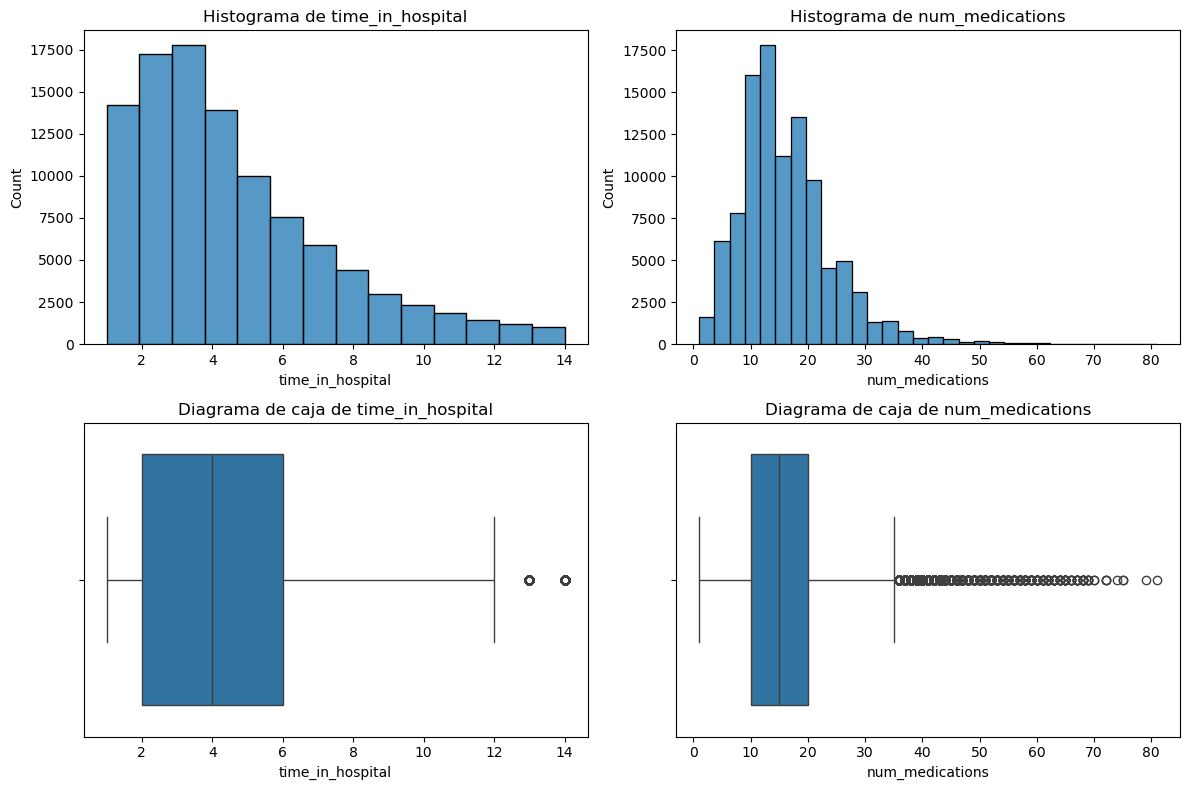

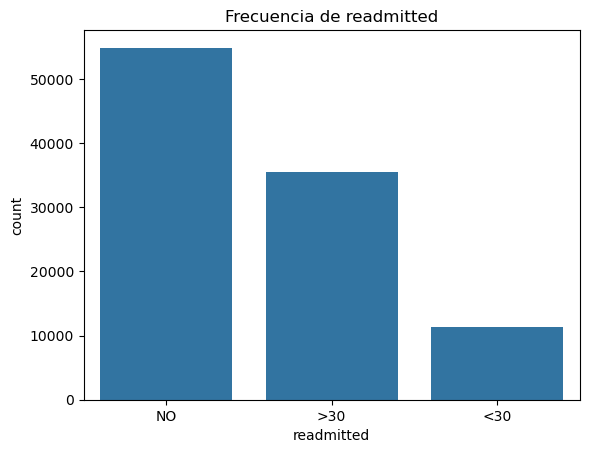

In [9]:
# Elegimos dos variables para la graficar

v1, v2 = "time_in_hospital", "num_medications"

# Figura de 2x2: histogramas(arriba) y diagramas de caja(abajo)
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

# Histograma de la primera variable
sns.histplot(df[v1], bins=14, ax=ax[0, 0])
ax[0, 0].set_title(f"Histograma de {v1}")

# Histograma de la segunda variable
sns.histplot(df[v2], bins=30, ax=ax[0, 1])
ax[0, 1].set_title(f"Histograma de {v2}")

# Diagrama de caja de la primera variable
sns.boxplot(x=df[v1], ax=ax[1, 0])
ax[1, 0].set_title(f"Diagrama de caja de {v1}")

# Diagrama de caja de la segunda variable
sns.boxplot(x=df[v2], ax=ax[1, 1])
ax[1, 1].set_title(f"Diagrama de caja de {v2}")
plt.tight_layout()
plt.show()

# Gráfico de frecuencias de readmitted
sns.countplot(x="readmitted", data=df, order=["NO", ">30", "<30"])
plt.title("Frecuencia de readmitted")
plt.show()

**Interpretación:** 
-**Histograma de "time_in_hospital":** La distribución es asimétrica hacia la derecha. Ya que la mayoría de las hospitalizaciones dura entre 1 y 4 días y la frecuencia baja gradualmente hasta los 14 días.
- **Diagrama de caja de "time_in_hospital":** La mediana es de 4 días y la caja va de 2 a 6. El bigote llega hasta 12 y los puntos atípicos aparecen entre 13 y 14 días.
- **Histograma de "num_medications":** También es asimétrico hacia la derecha. Aqui la mayor parte se concentra entre 10 y 20 medicamentos, con una cola larga que llega hasta 80,81.
- **Diagrama de caja de "num_medications":** La mediana es 15 y la caja va de 10 a 20, del 35 en adelante aparecen muchos puntos atípicos, que se extienden hasta 81.
- **Frecuencia de "readmitted":** La categoría **NO** es la más alta alrededor de 55000, luego **>30** esta alrededor de 35000 y por último **<30** alrededor de 11 000.

## Valores atípicos con IQR

In [10]:
# Box plot devuelve la posición de los outliers
def find_limits_BP(variable):
    
    Q1 = stats.scoreatpercentile(variable, 25)
    Q3 = stats.scoreatpercentile(variable, 75)
    RIC = Q3 - Q1

    li = Q1 - 1.5 * RIC
    ls = Q3 + 1.5 * RIC

    # Posiciones por debajo del limite inferior y por encima del superior
    pos_i = np.where(variable < li)[0]
    pos_s = np.where(variable > ls)[0]
    
    return np.concatenate((pos_i, pos_s))

# Recorremos cada variable y guardamos limites, cantidad y porcentaje de outliers
resultados = []
for col in cols_num:
    serie = df[col]
    pos = find_limits_BP(serie)                      
    Q1 = stats.scoreatpercentile(serie, 25)
    Q3 = stats.scoreatpercentile(serie, 75)
    RIC = Q3 - Q1
    resultados.append({
        "variable": col,
        "limite_inferior": Q1 - 1.5 * RIC,
        "limite_superior": Q3 + 1.5 * RIC,
        "n_outliers": len(pos),                     
        "porcentaje": round(len(pos) / len(df) * 100, 2),
    })
    
display(pd.DataFrame(resultados))

,variable,limite_inferior,limite_superior,n_outliers,porcentaje
0,time_in_hospital,-4.0,12.0,2252,2.21
1,num_lab_procedures,-8.0,96.0,143,0.14
2,num_procedures,-3.0,5.0,4954,4.87
3,num_medications,-5.0,35.0,2557,2.51
4,number_outpatient,0.0,0.0,16739,16.45
5,number_emergency,0.0,0.0,11383,11.19
6,number_inpatient,-1.5,2.5,7049,6.93


**Justificación:**
- **time_in_hospital:** Los outliers valores altos son las hospitalizaciones de 13 y 14 días, son datos reales por lo que **se conservan**.
  
- **num_medications:** Son pacientes con mas de 35 medicamentos los cuales corresponden a casos complejos, no son errores **se conservan**.

- **Visitas previas:** Como la mayoría tiene cero visitas, el método IQR marca cualquier valor mayor como atípico.Por eso aparecen porcentajes altos (16,45 % y 11,19 %). El método IQR aqui no es adecuado para conteos con mayoría de ceros, no son errores, son pacientes con visitas reales **se conservan**.

- 
- Todos los valores detectados están por encima del rango normal; no existen valores negativos.

**Decisión:** No se elimina ningún registro, ya que estos valores se tendrán en cuenta al momento de normalizar o estandarizar los datos.

# Paso 4. Fase 3: Selección y limpieza
Reglas explícitas y registro de filas y columnas antes y después de cada decisión.

In [11]:
# Lista donde guardamos el registro de limpieza
registro = []

def registrar(decision, antes, despues):
    # Guarda las filas y columnas que había antes y después de cada decisión
    registro.append({
        "decision": decision,
        "filas_antes": antes[0], "columnas_antes": antes[1],
        "filas_despues": despues[0], "columnas_despues": despues[1],
    })

# Trabajamos sobre una copia df queda intacto como copia original
df_clean = df.copy()

# Regla 1. duplicados se eliminan SOLO las filas que estan duplicadas.
# Los patient_nbr repetidos NO se eliminan por que son hospitalizaciones validas.
antes = df_clean.shape
df_clean = df_clean.drop_duplicates()
registrar("Eliminar filas duplicadas", antes, df_clean.shape)
print("Filas duplicadas eliminadas:", antes[0] - df_clean.shape[0])

# Regla 2. faltantes weight tiene cerca de 97 % de faltantes, se excluye del análisis
antes = df_clean.shape
df_clean = df_clean.drop(columns=["weight"])
registrar("Excluir la columna weight (96.86 % de faltantes)", antes, df_clean.shape)

# Regla 3. faltantes en max_glu_serum y A1Cresult el nulo significa "prueba no realizada"
antes = df_clean.shape
for col in ["max_glu_serum", "A1Cresult"]:
    df_clean[col] = df_clean[col].fillna("No medido")
registrar("Recodificar nulos de max_glu_serum y A1Cresult como 'No medido'", antes, df_clean.shape)

# Regla 4. faltantes race, payer_code, medical_specialty y diag_1/2/3 se conservan con sus nulos
# porque no se usan en el escalamiento y no se inventan datos
registrar("Conservar nulos de race, payer_code, medical_specialty y diag_1/2/3", df_clean.shape, df_clean.shape)

# Regla 5. inconsistencias revisamos valores imposibles en las variables numéricas
print("Valores negativos en las 7 variables:", (df_clean[cols_num] < 0).sum().sum())
print("time_in_hospital fuera de 1 a 14 días:", (~df_clean["time_in_hospital"].between(1, 14)).sum())
print("gender = Unknown/Invalid:", (df_clean["gender"] == "Unknown/Invalid").sum())
registrar("Revisar inconsistencias (no se elimina ninguna fila)", df_clean.shape, df_clean.shape)

# Regla 6. tipos los codigos de admisión, alta y origen son categorias, no mediciones
antes = df_clean.shape
cols_codigo = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
for col in cols_codigo:
    df_clean[col] = df_clean[col].astype("category")
registrar("Cambiar a tipo category los códigos de admisión, alta y origen", antes, df_clean.shape)
print(df_clean[cols_codigo].dtypes)

# Registro de limpieza completo
display(pd.DataFrame(registro))

# Comprobacion de filas y nulos
print("Filas finales:", df_clean.shape[0])
assert df_clean.shape[0] > 100_000, "Tras la limpieza el dataset debe seguir superando 100 000 filas."
print("Nulos en las 7 variables numéricas:", df_clean[cols_num].isna().sum().sum())

Filas duplicadas eliminadas: 0
Valores negativos en las 7 variables: 0
time_in_hospital fuera de 1 a 14 días: 0
gender = Unknown/Invalid: 3
admission_type_id           category
discharge_disposition_id    category
admission_source_id         category
dtype: object


,decision,filas_antes,columnas_antes,filas_despues,columnas_despues
0,Eliminar filas duplicadas,101766,50,101766,50
1,Excluir la columna weight (96.86 % de faltantes),101766,50,101766,49
2,Recodificar nulos de max_glu_serum y A1Cresult como 'No medido',101766,49,101766,49
3,"Conservar nulos de race, payer_code, medical_specialty y diag_1/2/3",101766,49,101766,49
4,Revisar inconsistencias (no se elimina ninguna fila),101766,49,101766,49
5,"Cambiar a tipo category los códigos de admisión, alta y origen",101766,49,101766,49


Filas finales: 101766
Nulos en las 7 variables numéricas: 0


**Justificación:** No se encontraron filas duplicadas, valores negativos ni estancias fuera de rango. Solo se eliminó la columna **weight** por tener casi un 97% de datos faltantes. Los valores perdidos en pruebas médicas se recodificaron como “No medido”, mientras que los valores perdidos en otras variables se dejaron como estaban. Se ajustaron los tipos de datos, sin descartar ningún registro. Al final quedaron conservadas las **101 766 filas originales**.

# Paso 5. Selección de variables cuantitativas

In [12]:
# Seleccionamos las 7 variables cuantitativas limpias (sin identificadores ni categorías)
# X es la copia de las variables numéricas limpias ANTES de transformar
X = df_clean[cols_num].copy()

print("Forma de X:", X.shape)
print(X.dtypes)
print("Nulos por variable:")
print(X.isnull().sum())

# Comprobamos que no entró ningún identificador ni código categórico
excluidas = ["encounter_id", "patient_nbr", "admission_type_id",
             "discharge_disposition_id", "admission_source_id", "age"]
print("¿Alguna variable excluida dentro de X?:", any(c in X.columns for c in excluidas))

# Guardamos la copia de las variables numéricas limpias, antes de transformar
X.to_csv("variables_numericas_limpias.csv", index=True, index_label="indice_referencia")
display(X.head())

Forma de X: (101766, 7)
time_in_hospital      int64
num_lab_procedures    int64
num_procedures        int64
num_medications       int64
number_outpatient     int64
number_emergency      int64
number_inpatient      int64
dtype: object
Nulos por variable:
time_in_hospital      0
num_lab_procedures    0
num_procedures        0
num_medications       0
number_outpatient     0
number_emergency      0
number_inpatient      0
dtype: int64
¿Alguna variable excluida dentro de X?: False


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,1,41,0,1,0,0,0
1,3,59,0,18,0,0,0
2,2,11,5,13,2,0,1
3,2,44,1,16,0,0,0
4,1,51,0,8,0,0,0


**Interpretación:** Se seleccionaron las 7 variables cuantitativas ("int64", 101 766 filas y sin nulos) y se guardó una copia limpia en **variables_numericas_limpias.csv** antes de transformar.

- **Identificadores** El **encounter_id, patient_nbr** sirven para nombrar filas y pacientes no hay ningún valor que midan, por lo que escalarlos no tendría sentido.

- **Códigos de admisión, de alta y de origen:** Son categorías que se representan con números. Escalarlos crearía una falsa distancia entre las categorías.
  
- **age:** se presenta en saltos de 10 años, por lo que se considera una variable ordinal categórica, no una edad continua.

# Paso 6. Normalización Min-Max
**Formula:**
$X_j^N = \frac{X_{ij} - \min(X_j)}{\max(X_j) - \min(X_j)}$

In [19]:
from sklearn import preprocessing

# Normalizamos Min-Max en el rango [0, 1] 

normalizer = preprocessing.MinMaxScaler(feature_range=(0, 1))
X_norm = normalizer.fit_transform(X)

# Conservamos nombres de columnas y el índice (filas)
X_norm = pd.DataFrame(X_norm, columns=X.columns, index=X.index)

# Primeras diez filas transformadas
display(X_norm.head(10))

# Tabla mínimo y máximo antes y despues
tabla_minmax = pd.DataFrame({
    "min_antes": X.min(), "max_antes": X.max(),
    "min_despues": X_norm.min(), "max_despues": X_norm.max(),
})
display(tabla_minmax)

# Columnas constantes (máximo = mínimo), denominador de Min-Max cero
constantes = X.columns[X.nunique() == 1]
no_const = [c for c in X.columns if c not in constantes]
print("Columnas constantes:", list(constantes))

# Comprobación del rango mediante tolerancia numérica
ok_min = np.isclose(X_norm[no_const].min(), 0, atol=1e-9).all()
ok_max = np.isclose(X_norm[no_const].max(), 1, atol=1e-9).all()
print("¿Mínimos = 0 y máximos = 1?:", ok_min and ok_max)
print("¿Todos los valores dentro de [0, 1]?:",
      ((X_norm >= -1e-9) & (X_norm <= 1 + 1e-9)).all().all())

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,0.000000,0.305344,0.000000,0.0000,0.000000,0.0,0.000000
1,0.153846,0.442748,0.000000,0.2125,0.000000,0.0,0.000000
2,0.076923,0.076336,0.833333,0.1500,0.047619,0.0,0.047619
3,0.076923,0.328244,0.166667,0.1875,0.000000,0.0,0.000000
4,0.000000,0.381679,0.000000,0.0875,0.000000,0.0,0.000000
5,0.153846,0.229008,1.000000,0.1875,0.000000,0.0,0.000000
6,0.230769,0.526718,0.166667,0.2500,0.000000,0.0,0.000000
7,0.307692,0.549618,0.000000,0.1375,0.000000,0.0,0.000000
8,0.923077,0.511450,0.333333,0.3375,0.000000,0.0,0.000000
9,0.846154,0.244275,0.500000,0.2125,0.000000,0.0,0.000000


,min_antes,max_antes,min_despues,max_despues
time_in_hospital,1,14,0.0,1.0
num_lab_procedures,1,132,0.0,1.0
num_procedures,0,6,0.0,1.0
num_medications,1,81,0.0,1.0
number_outpatient,0,42,0.0,1.0
number_emergency,0,76,0.0,1.0
number_inpatient,0,21,0.0,1.0


Columnas constantes: []
¿Mínimos = 0 y máximos = 1?: True
¿Todos los valores dentro de [0, 1]?: True


**Explicación:** Min-Max dejó todas las variables en el rango [0, 1] mínimos en 0 y máximos en 1, comprobado con tolerancia numerica.

- **Influencia de los valores extremos:** Min-Max usa el mínimo y el máximo para calcular la escala, así que un valor extremo comprime al resto de los datos. En **number_emergency** (máximo 76) y **number_outpatient** (máximo 42), casi todos los valores quedan pegados a 0: sus medias son 0,0026 y 0,0088. En cambio, **time_in_hospital** (máximo 14) aprovecha más el rango, con una media de 0,2612.
  
- **Columna constante:** si todos los valores de una columna fueran iguales, el máximo sería igual al mínimo y el denominador sería 0, es decir, una división por cero. Aquí no hay ninguna columna constante (la lista salió vacía). Si la hubiera, `MinMaxScaler` evita el error y deja la columna en 0.

# Paso 7. Estandarización Z-score
Fórmula: z = (x − μ) / σ

In [20]:
# Estandarizamos con Z-score sobre otra copia de X 
standarizer = preprocessing.StandardScaler()
X_std = standarizer.fit_transform(X)

# Conservamos nombres de columnas e indice
X_std = pd.DataFrame(X_std, columns=X.columns, index=X.index)

# Primeras diez filas transformadas
display(X_std.head(10))

# Media y desviación estándar usando (ddof=0 ) para concordar con StandardScaler
media = X_std.mean()
desviacion = X_std.std(ddof=0)
print("Media:")
print(media.round(6))
print("Desviacion estandar:")
print(desviacion.round(6))

# Comprobacion mediante tolerancias
print("¿Media aproximadamente 0?:", np.isclose(media, 0, atol=1e-9).all())
print("¿Desviacion aproximadamente 1 (no constantes)?:",
      np.isclose(desviacion[no_const], 1, atol=1e-9).all())

# Valores negativos y valores fuera del intervalo [0, 1]
print("¿Hay valores negativos?:", (X_std < 0).any().any())
print("¿Hay valores fuera de [0, 1]?:", ((X_std < 0) | (X_std > 1)).any().any())

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,-1.137649,-0.106517,-0.785398,-1.848268,-0.291461,-0.21262,-0.503276
1,-0.467653,0.808384,-0.785398,0.243390,-0.291461,-0.21262,-0.503276
2,-0.802651,-1.631351,2.145781,-0.371804,1.286748,-0.21262,0.288579
3,-0.802651,0.045967,-0.199162,-0.002688,-0.291461,-0.21262,-0.503276
4,-1.137649,0.401761,-0.785398,-0.986997,-0.291461,-0.21262,-0.503276
5,-0.467653,-0.614795,2.732016,-0.002688,-0.291461,-0.21262,-0.503276
6,-0.132655,1.367490,-0.199162,0.612506,-0.291461,-0.21262,-0.503276
7,0.202343,1.519973,-0.785398,-0.494842,-0.291461,-0.21262,-0.503276
8,2.882327,1.265834,0.387074,1.473776,-0.291461,-0.21262,-0.503276
9,2.547329,-0.513139,0.973309,0.243390,-0.291461,-0.21262,-0.503276


Media:
time_in_hospital      0.0
num_lab_procedures    0.0
num_procedures       -0.0
num_medications      -0.0
number_outpatient     0.0
number_emergency      0.0
number_inpatient     -0.0
dtype: float64
Desviacion estandar:
time_in_hospital      1.0
num_lab_procedures    1.0
num_procedures        1.0
num_medications       1.0
number_outpatient     1.0
number_emergency      1.0
number_inpatient      1.0
dtype: float64
¿Media aproximadamente 0?: True
¿Desviacion aproximadamente 1 (no constantes)?: True
¿Hay valores negativos?: True
¿Hay valores fuera de [0, 1]?: True


**Explicación:** La estandarización Z-score ajustó todas las variables a una media de 0 y desviación estándar de 1(comprobado con tolerancias y **ddof=0**).

- **Valores negativos:** Es negativo si el valor es inferior a la media. Por ejemplo una hospitalización de 1 día queda en −1,14 desviaciones de la media.
  
- **Valores fuera de [0, 1]:** El Z-score no tiene un rango fijo, al contrario que Min-Max. Los valores pueden estar a varias desviaciones de la media: el máximo de **num_medications** se encuentra alrededor de 8 y el de **number_emergency** en torno a 81.

- **Columna constante:** Si todos los valores fueran iguales, la desviación sería 0 y StandardScaler dejaría la columna en 0. Aquí no hay ninguna columna constante.

# Paso 8. Comparación y exportación

In [21]:
# Tabla comparativa de: mínimo, máximo, media y desviación estándar
versiones = {"original": X, "normalizado": X_norm, "estandarizado": X_std}
comparacion = pd.concat(
    {nombre: pd.DataFrame({"min": d.min(), "max": d.max(),
                           "media": d.mean(), "desviacion": d.std(ddof=0)})
     for nombre, d in versiones.items()},
    axis=1)
display(comparacion.round(4))

original                          normalizado               \
                        min  max    media desviacion         min  max   media   
time_in_hospital          1   14   4.3960     2.9851         0.0  1.0  0.2612   
num_lab_procedures        1  132  43.0956    19.6743         0.0  1.0  0.3213   
num_procedures            0    6   1.3397     1.7058         0.0  1.0  0.2233   
num_medications           1   81  16.0218     8.1275         0.0  1.0  0.1878   
number_outpatient         0   42   0.3694     1.2673         0.0  1.0  0.0088   
number_emergency          0   76   0.1978     0.9305         0.0  1.0  0.0026   
number_inpatient          0   21   0.6356     1.2629         0.0  1.0  0.0303   

                              estandarizado                            
                   desviacion           min      max media desviacion  
time_in_hospital       0.2296       -1.1376   3.2173   0.0        1.0  
num_lab_procedures     0.1502       -2.1396   4.5188   0.0        1.0  
num_procedures         0.2843       -0.7854   2.7320  -0.0        1.0  
num_medications        0.1016       -1.8483   7.9948  -0.0        1.0  
number_outpatient      0.0302       -0.2915  32.8509   0.0        1.0  
number_emergency       0.0122       -0.2126  81.4667   0.0        1.0  
number_inpatient       0.0601       -0.5033  16.1257  -0.0        1.0

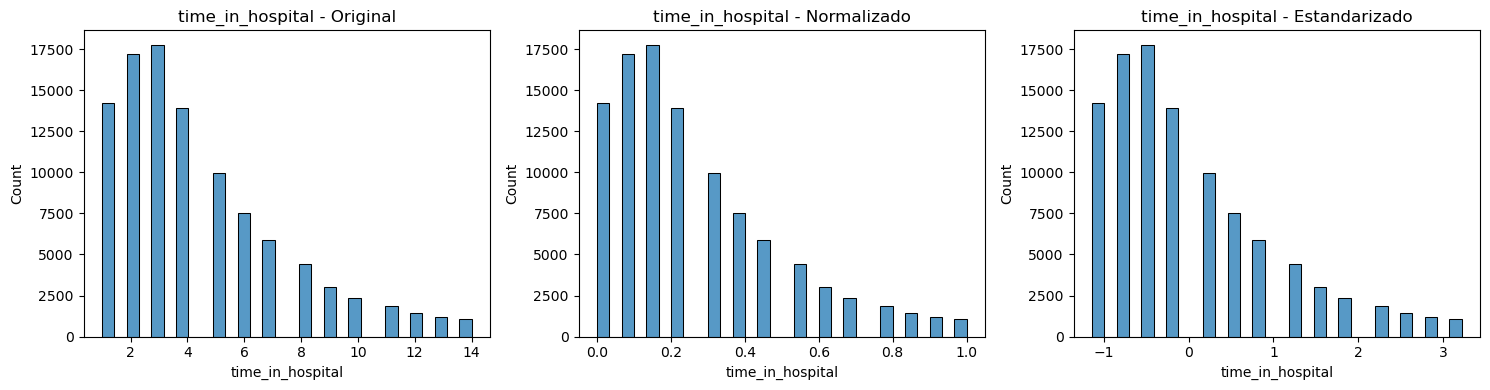

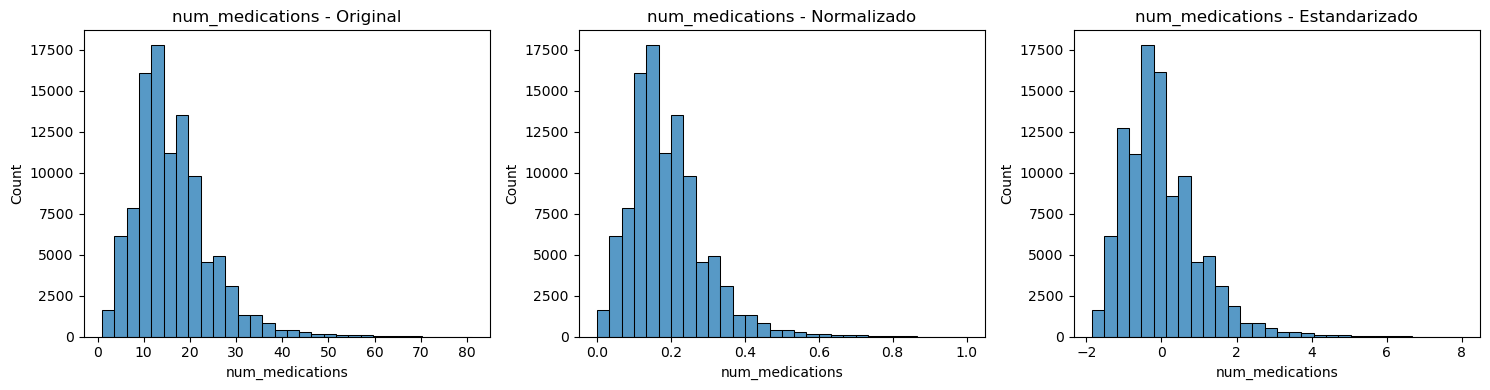

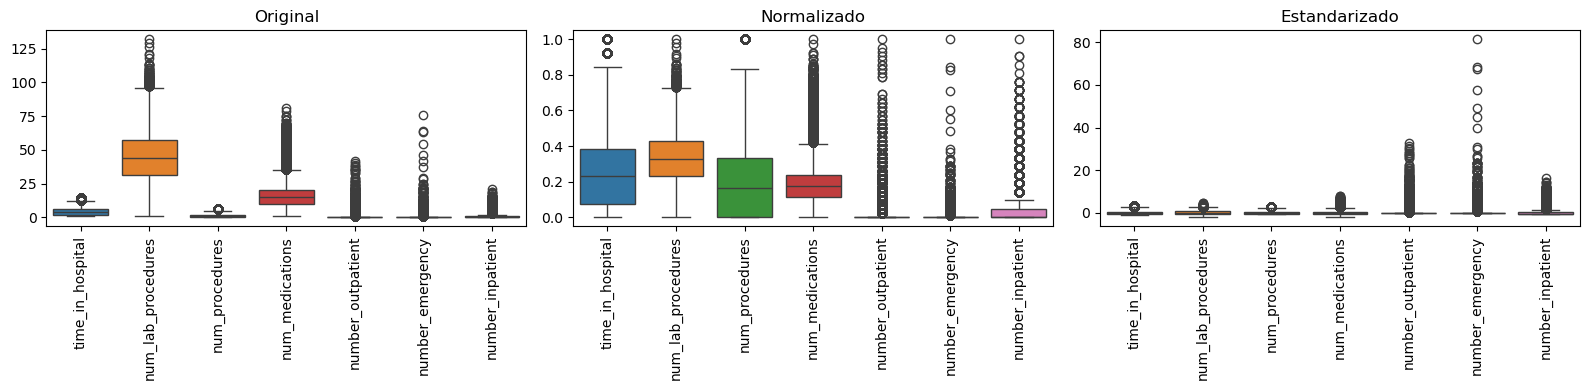

In [22]:
# Gráficos comparables de dos variables: original, normalizado y estandarizado
for var in ["time_in_hospital", "num_medications"]:
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    sns.histplot(X[var], bins=30, ax=ax[0])
    ax[0].set_title(f"{var} - Original")
    sns.histplot(X_norm[var], bins=30, ax=ax[1])
    ax[1].set_title(f"{var} - Normalizado")
    sns.histplot(X_std[var], bins=30, ax=ax[2])
    ax[2].set_title(f"{var} - Estandarizado")
    plt.tight_layout()
    plt.show()

# Comparación visual con diagramas de caja de las 7 variables
plt.figure(figsize=(16, 4))
plt.subplot(1, 3, 1)
sns.boxplot(data=X)
plt.title("Original")
plt.xticks(rotation=90)
plt.subplot(1, 3, 2)
sns.boxplot(data=X_norm)
plt.title("Normalizado")
plt.xticks(rotation=90)
plt.subplot(1, 3, 3)
sns.boxplot(data=X_std)
plt.title("Estandarizado")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Interpretación:** 

- **Cambio de escala:** En la tabla comparativa, los valores originales tienen rangos muy distintos como por ejemplo, **num_lab_procedures** llega a 132 y **num_procedures** a 6. Con Min-Max todas pasan al rango [0, 1] y con Z-score todas quedan con media 0 y desviación 1, lo que las hace comparables.
  
- **Forma de la distribución:** En **time_in_hospital** y **num_medications** los tres histogramas tienen la misma forma, con asimetría hacia la derecha. Lo que cambian son los ejes: **time_in_hospital** pasa de 1–14 a 0–1 y a aproximadamente −1,14 a 3,22, **num_medications** pasa de 1–81 a 0–1 y a aproximadamente −1,85 a 8. Esto ocurre porque ambas son transformaciones lineales es decir modifican la escala y la posición, pero no las distancias relativas entre los datos y los valores atípicos se mantienen.

- **Diagramas de caja:** En los datos originales, **num_lab_procedures** domina la escala y las demás se ven bajos. Con Min-Max todas comparten el rango [0, 1], pero las visitas previas quedan comprimidas cerca de 0 por sus valores extremos. Con Z-score, el **number_emergency** llega hasta aproximadamente 80 y las demás variables se ven pegadas al 0. Los valores atípicos siguen existiendo en las tres versiones.

In [23]:
# Demostración manual con cinco valores de una variable
var = "time_in_hospital"
muestra = X[var].iloc[:5]

# Parámetros usados por los escaladores
x_min, x_max = X[var].min(), X[var].max()
mu, sigma = X[var].mean(), X[var].std(ddof=0)
print(f"Parametros de {var}: minimo={x_min}, maximo={x_max}, media={mu:.4f}, desviaci0n={sigma:.4f}")

# Calculo manual de Min-Max y de Z-score
manual_norm = (muestra - x_min) / (x_max - x_min)
manual_std = (muestra - mu) / sigma

# Contraste con las salidas de Python
demo = pd.DataFrame({
    "x": muestra,
    "min-max manual": manual_norm,
    "min-max Python": X_norm[var].iloc[:5],
    "z manual": manual_std,
    "z Python": X_std[var].iloc[:5],
})
display(demo)
print("¿Min-Max manual = Python?:", np.allclose(manual_norm, X_norm[var].iloc[:5]))
print("¿Z-score manual = Python?:", np.allclose(manual_std, X_std[var].iloc[:5]))

Parametros de time_in_hospital: minimo=1, maximo=14, media=4.3960, desviaci0n=2.9851


,x,min-max manual,min-max Python,z manual,z Python
0,1,0.000000,0.000000,-1.137649,-1.137649
1,3,0.153846,0.153846,-0.467653,-0.467653
2,2,0.076923,0.076923,-0.802651,-0.802651
3,2,0.076923,0.076923,-0.802651,-0.802651
4,1,0.000000,0.000000,-1.137649,-1.137649


¿Min-Max manual = Python?: True
¿Z-score manual = Python?: True


**Explicación:** Con los parámetros de **time_in_hospital** (mínimo 1, máximo 14, media 4,3960 y desviación 2,9851), el cálculo manual coincide con la salida de Python. Ejemplo si para x = 3: Min-Max = (3 − 1) / (14 − 1) = 0,1538 y Z-score = (3 − 4,3960) / 2,9851 = −0,4677. Las comprobaciones dieron True en ambos casos.

In [24]:
# Exportamos las dos versiones con el mismo orden de filas y el índice de referencia
X_norm.to_csv("datos_normalizados.csv", index=True, index_label="indice_referencia")
X_std.to_csv("datos_estandarizados.csv", index=True, index_label="indice_referencia")

# Tabla de registros originales
correspondencia = df_clean.loc[X.index, ["encounter_id", "patient_nbr"]]
correspondencia.to_csv("correspondencia_registros.csv", index=True, index_label="indice_referencia")

# Comprobamos que los archivos exportados tengan el mismo indice, orden y columnas
n = pd.read_csv("datos_normalizados.csv", index_col="indice_referencia")
e = pd.read_csv("datos_estandarizados.csv", index_col="indice_referencia")
print("Filas y columnas:", n.shape, e.shape)
print("¿Mismo indice y orden en ambos archivos?:", n.index.equals(e.index))
print("¿Mismo indice que las variables limpias?:", n.index.equals(X.index))
print("¿Mismas columnas y orden?:", list(n.columns) == list(e.columns) == cols_num)

Filas y columnas: (101766, 7) (101766, 7)
¿Mismo indice y orden en ambos archivos?: True
¿Mismo indice que las variables limpias?: True
¿Mismas columnas y orden?: True


**Respuesta a las preguntas de análisis:**

1. **¿Qué variables presentan escalas distintas y qué valores atípicos tienen según el método IQR?**

Las 7 variables tienen escalas muy distintas: **num_lab_procedures** media 43,1 y máximo 132 y **num_medications** media 16,0 y máximo 81 tienen valores mucho mayores que **time_in_hospital** 1 a 14, **num_procedures** 0 a 6 y las visitas previas medias menores a 1. Con el método IQR todas tienen valores atípicos superiores, entre 0,14 % **num_lab_procedures** y 16,45 % **number_outpatient**. En las variables de visitas previas, el IQR marca como valor atípico en **number_outpatient y number_emergency**, cualquier valor distinto de cero. Estos valores se mantuvieron en el conjunto de datos, ya que corresponden a casos reales y no a errores de registro.

2. **¿Se conserva la forma de la distribución al aplicar normalización Min-Max y estandarización Z-score?** 
 
Sí. Tanto Min-Max como Z-score son transformaciones lineales, por lo que los histogramas mantienen exactamente la misma forma, con asimetría hacia la derecha, y lo único que cambia son las escalas de los ejes. Ninguno de los dos métodos elimina los valores atípicos ni corrige la asimetría de los datos.

# Conclusiones

En esta práctica se prepararon 7 variables cuantitativas de más de 100 000 hospitalizaciones de pacientes con diabetes, aplicando las fases iniciales de CRISP-DM. Revisamos y limpiamos los datos sin perder ningún registro y vimos que las variables tienen escalas muy distintas, además de valores atípicos que son casos clínicos reales y no errores, por lo que los conservamos. Después aplicamos Min-Max y Z-score, que dejaron todas las variables en una escala comparable.

Los metodos Min-Max y Z-score solo cambian la escala y no la forma de los datos, por lo que la asimetría y los valores atípicos siguen presentes. Min-Max es útil cuando necesitamos que todo esté dentro de un rango fijo entre 0 y 1, mientras que Z-score ayuda a comparar que tan lejos está cada valor del promedio. 

También es importante mencionar las limitaciones del estudio ya que los datos corresponden a hospitales de Estados Unidos entre 1999 y 2008, y un mismo paciente puede aparecer varias veces, por lo que no todos los registros son independientes. Además, la variable de peso tuvo que descartarse por la gran cantidad de información faltante. Este análisis es solo descriptivo, así que no podemos determinar relaciones de causa y efecto.

# Preguntas de reflexión
1. **¿Por qué un código categórico numérico no debe escalarse como una medición?**

Porque esos números son solo etiquetas, no cantidades. Por ejemplo, el tipo de admisión 3 no es mayor que el 1. Si los escalamos, el modelo creería que hay una relación entre ellos cuando no existe, y eso generaría información falsa.
   
2. **¿Cómo afectaría un valor extremo a Min-Max y a Z-score?**

Con Min-Max, el valor se convierte en el rango tope y comprime a todo lo demás cerca del 0 y 1. Con Z-score, en cambio, arrastra el promedio y aumenta la dispersión, haciendo que ese valor quede muy alejado del resto. En ambos casos, los demás datos terminan muy juntos.
   
3. **¿Por qué una readmisión del mismo paciente no es necesariamente un duplicado?**

Porque cada vez que un paciente ingresa al hospital queda registrado con su propio código, por lo que son eventos distintos. Si los borráramos por ser del mismo paciente, perderíamos información real de sus hospitalizaciones. Lo que sí implica es que las filas no son totalmente independientes entre sí.
   
4. **¿Qué diferencia hay entre cambiar de escala y corregir una distribución asimétrica?**

Cambiar de escala (Min-Max o Z-score) es una transformación lineal, ya que modifica el rango y las unidades pero no la forma. Como se vio en los histogramas, donde la asimetría hacia la derecha sigue igual. Si lo que queremos es reducir esa asimetría, necesitamos otra clase de transformaciones, como usar el logaritmo o la raíz cuadrada.
   
5. **¿Cómo evitaría la fuga de información si posteriormente entrenara un modelo?**
   
Separaría mis datos en dos grupos uno para entrenar y otro para probar. Calcularía los valores de normalización solo con el grupo de entrenamiento y aplicaría lo mismo al de prueba. También me aseguraría de que los mismos pacientes no aparezcan en ambos grupos al mismo tiempo.
   

# Fuente

- https://onlinelibrary.wiley.com/doi/10.1155/2014/781670
- https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008